In [1]:
import pandas as pd
import rdkit
from rdkit import Chem
from rdkit.Chem import rdRGroupDecomposition
from rdkit.Chem.Draw import IPythonConsole
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG, display
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.Chem import Draw, AllChem
from rdkit.Chem import rdDepictor
from itertools import product # for generating all possible combinations
from rdkit.Geometry import Point2D
import requests

#### Enter the Molecule of interest

In [2]:
parent_smiles = input("Enter the SMILES of the molecule: ")
mol = Chem.MolFromSmiles(parent_smiles)

if mol is None:
    print("Invalid Molecule")

else:
    print("________________________________")
    print("Hurray!! its a valid molecule")
    print(f"The entered SMILES is {parent_smiles}")
    print(f"Canonical SMILES: {Chem.MolToSmiles(mol)}")

________________________________
Hurray!! its a valid molecule
The entered SMILES is CC(=O)NC1=CC=C(C=C1)O
Canonical SMILES: CC(=O)Nc1ccc(O)cc1


#### Visualizing the molecule

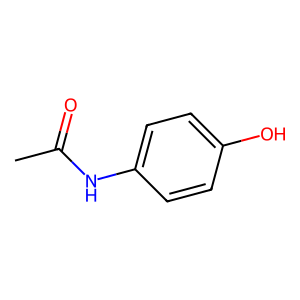

In [3]:
Draw.MolToImage(mol)

In [4]:
parent_mol = Chem.Mol(mol)
print(mol)
print(parent_mol)

#### Setting original index to track the atoms and bond indices 

In [5]:
def set_original_idx(mol):

    for atom in mol.GetAtoms():
        atom.SetIntProp("original_idx", atom.GetIdx())
        atom.SetProp("molAtomMapNumber", str(atom.GetIdx()))

    return mol

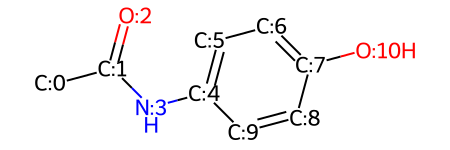

In [6]:
set_original_idx(parent_mol)

In [7]:
def set_original_bond_idx(mol):

    for bond in mol.GetBonds():
        bond.SetIntProp("original_bond_idx", bond.GetIdx())
        bond.SetProp("molBondMapNumber", str(bond.GetIdx()))

    return mol

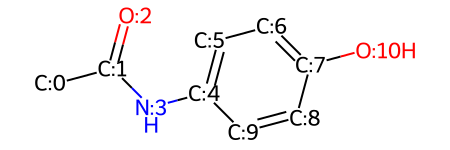

In [8]:
set_original_bond_idx(parent_mol)
parent_mol

#### Functions to track the molecule

In [9]:
def find_current_idx(mol, original_idx):
    for atom in mol.GetAtoms():
        if atom.HasProp("original_idx"): 
            if atom.GetIntProp("original_idx") == original_idx:
                return atom.GetIdx()
    return None

In [10]:
def find_current_bond_idx(mol, original_bond_idx):
    for bond in mol.GetBonds():
        if bond.HasProp("original_bond_idx"):
            if bond.GetIntProp("original_bond_idx") == original_bond_idx:
                return bond.GetIdx()
    return None    

In [11]:
def draw_with_original_bond_indices(mol, width=500, height=400):

    # Make sure the molecule has 2D coordinates
    if not mol.GetNumConformers():
        Chem.rdDepictor.Compute2DCoords(mol)

    # Create SVG drawer
    drawer = rdMolDraw2D.MolDraw2DSVG(width, height)

    # Drawing options
    opts = drawer.drawOptions()

    # Do not show RDKit's current bond indices
    opts.addBondIndices = False

    # Draw the molecule first
    drawer.DrawMolecule(mol)

    # Set font size for our bond numbers
    drawer.SetFontSize(14)

    # Set text colour
    drawer.SetColour((1.0, 0.0, 0.0))

    # Get 2D coordinates
    conf = mol.GetConformer()

    # Add original bond indices
    for bond in mol.GetBonds():

        # Check whether the bond has our original index
        if not bond.HasProp("original_bond_idx"):
            continue

        original_idx = bond.GetIntProp("original_bond_idx")

        # Get the two atoms connected by this bond
        atom1_idx = bond.GetBeginAtomIdx()
        atom2_idx = bond.GetEndAtomIdx()

        pos1 = conf.GetAtomPosition(atom1_idx)
        pos2 = conf.GetAtomPosition(atom2_idx)

        # Calculate midpoint of the bond
        mid_x = (pos1.x + pos2.x) / 2
        mid_y = (pos1.y + pos2.y) / 2

        # Calculate bond direction
        dx = pos2.x - pos1.x
        dy = pos2.y - pos1.y

        # Calculate bond length
        length = (dx**2 + dy**2) ** 0.5

        if length != 0:

            # Perpendicular direction
            perp_x = -dy / length
            perp_y = dx / length

            # Move label slightly away from the bond
            offset = 0.15

            label_x = mid_x + perp_x * offset
            label_y = mid_y + perp_y * offset

        else:
            label_x = mid_x
            label_y = mid_y

        # Position for label
        label_position = Point2D(label_x, label_y)

        # Draw original bond number
        drawer.DrawString(
            str(original_idx),
            label_position
        )

    # Finish drawing
    drawer.FinishDrawing()

    # Get SVG
    svg = drawer.GetDrawingText()

    # Display
    display(SVG(svg))

In [12]:
def get_core_dummy_info(mol):
    result = []

    for atom in mol.GetAtoms():

        if atom.GetSymbol() == "*":

            neighbor_data = {
                "core_dummy_current_idx": atom.GetIdx(),            
                "core_dummy_neighbor_current_idx": None,
                "core_dummy_neighbor_original_idx": None
            }

            neighbors = atom.GetNeighbors()

            if len(neighbors) > 0:
                neighbor = neighbors[0]

                neighbor_data["core_dummy_neighbor_current_idx"] = neighbor.GetIdx()

                if neighbor.HasProp("original_idx"):
                    neighbor_data["core_dummy_neighbor_original_idx"] = neighbor.GetIntProp("original_idx")

            result.append(neighbor_data)

    return result      

In [13]:
def get_replacement_dummy_info(mol):
    """
    Replacement groups are expected to contain exactly one dummy atom.
    """

    result = []

    for atom in mol.GetAtoms():

        if atom.GetSymbol() == "*":
           
            neighbors = atom.GetNeighbors()
            
            neighbor = neighbors[0]
                
            result.append({
                "replacement_dummy_current_idx":
                atom.GetIdx(),
                "replacement_dummy_neighbor_current_idx":
                neighbor.GetIdx()
            })
        
            return result       

In [14]:
def check_pubchem(smiles):

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return {
            "SMILES": smiles,
            "Status": "Invalid SMILES",
            "CID": None,
            "PubChem_URL": None
        }

    canonical_smiles = Chem.MolToSmiles(
        mol,
        canonical=True,
        isomericSmiles=True
    )

    url = (
        "https://pubchem.ncbi.nlm.nih.gov/rest/pug/"
        "compound/fastidentity/smiles/cids/JSON"
    )

    try:
        response = requests.post(
            url,
            data={"smiles": canonical_smiles},
            params={"identity_type": "same_stereo_isotope"},
            timeout=30
        )

        if response.status_code == 404:
            return {
                "SMILES": canonical_smiles,
                "Status": "Not found in PubChem",
                "CID": None,
                "PubChem_URL": None
            }

        response.raise_for_status()

        data = response.json()

        cids = data.get(
            "IdentifierList", {}
        ).get("CID", [])

        if cids:
            return {
                "SMILES": canonical_smiles,
                "Status": "Found",
                "CID": cids,
                "PubChem_URL": [
                    f"https://pubchem.ncbi.nlm.nih.gov/compound/{cid}"
                    for cid in cids
                ]
            }

        return {
            "SMILES": canonical_smiles,
            "Status": "Not found in PubChem",
            "CID": None,
            "PubChem_URL": None
        }

    except requests.RequestException as e:
        return {
            "SMILES": canonical_smiles,
            "Status": "API Error",
            "CID": None,
            "PubChem_URL": None,
            "Error": str(e)
        }


#### Options for replacement groups

In [15]:
def select_categories(dummy_number):

    print(f"\nSelect categories for dummy neighbor {dummy_number}")
    print("-------------------------------------------")

    for i, name in enumerate(categories):
        print(f"{i} | {name}")

    choices = input(
        "Enter 3-4 category numbers separated by commas: "
    )

    selected_indices = [
        int(x.strip()) for x in choices.split(",")
    ]

    selected_categories = [
        categories[i] for i in selected_indices
    ]

    print("Selected categories:", selected_categories)

    return selected_categories


def collect_replacements(selected_categories):

    selected_groups = {}

    for category in selected_categories:

        for name, smiles in replacement_groups[category].items():

            selected_groups[name] = smiles

    return selected_groups


def prepare_replacement_groups(selected_groups):

    prepared = []

    for name, smiles in selected_groups.items():

        mol = Chem.MolFromSmiles(smiles)

        prepared.append({
            "name": name,
            "smiles": smiles,
            "mol": mol
        })

    return prepared

In [16]:
replacement_groups = {

    # ============================================================
    # 1. HYDROGEN / ALKYL GROUPS
    # ============================================================
    "alkyl": {
        "methyl": "[*:1]C",
        "ethyl": "[*:1]CC",
        "n_propyl": "[*:1]CCC",
        "n_butyl": "[*:1]CCCC",
        "n_pentyl": "[*:1]CCCCC",
        "n_hexyl": "[*:1]CCCCCC",

        "isopropyl": "[*:1]C(C)C",
        "isobutyl": "[*:1]CC(C)C",
        "sec_butyl": "[*:1]C(C)CC",
        "tert_butyl": "[*:1]C(C)(C)C",

        "neopentyl": "[*:1]CC(C)(C)C",
        "2_methylbutyl": "[*:1]CC(C)CC",
        "3_methylbutyl": "[*:1]CCC(C)C",
    },


    # ============================================================
    # 2. CYCLOALKYL GROUPS
    # ============================================================
    "cycloalkyl": {
        "cyclopropyl": "[*:1]C1CC1",
        "cyclobutyl": "[*:1]C1CCC1",
        "cyclopentyl": "[*:1]C1CCCC1",
        "cyclohexyl": "[*:1]C1CCCCC1",
        "cycloheptyl": "[*:1]C1CCCCCC1",
        "cyclooctyl": "[*:1]C1CCCCCCC1",

        "cyclopropylmethyl": "[*:1]CC1CC1",
        "cyclobutylmethyl": "[*:1]CC1CCC1",
        "cyclopentylmethyl": "[*:1]CC1CCCC1",
        "cyclohexylmethyl": "[*:1]CC1CCCCC1",
    },


    # ============================================================
    # 3. ALKENYL / ALKYNYL GROUPS
    # ============================================================
    "alkenyl_alkynyl": {
        "vinyl": "[*:1]C=C",
        "allyl": "[*:1]CC=C",
        "propenyl": "[*:1]C=CC",
        "isopropenyl": "[*:1]C(C)=C",
        "butenyl": "[*:1]CCC=C",

        "ethynyl": "[*:1]C#C",
        "propynyl": "[*:1]CC#C",
        "butynyl": "[*:1]CCC#C",
    },


    # ============================================================
    # 4. HALOGENS
    # ============================================================
    "halogens": {
        "fluoro": "[*:1]F",
        "chloro": "[*:1]Cl",
        "bromo": "[*:1]Br",
        "iodo": "[*:1]I",
    },


    # ============================================================
    # 5. FLUOROALKYL GROUPS
    # ============================================================
    "fluoroalkyl": {
        "fluoromethyl": "[*:1]CF",
        "difluoromethyl": "[*:1]C(F)F",
        "trifluoromethyl": "[*:1]C(F)(F)F",

        "2_fluoroethyl": "[*:1]CCF",
        "2_difluoroethyl": "[*:1]CC(F)F",
        "2_trifluoroethyl": "[*:1]CC(F)(F)F",

        "pentafluoroethyl": "[*:1]C(F)(F)C(F)(F)F",
    },


    # ============================================================
    # 6. ALKOXY GROUPS
    # ============================================================
    "alkoxy": {
        "methoxy": "[*:1]OC",
        "ethoxy": "[*:1]OCC",
        "n_propoxy": "[*:1]OCCC",
        "isopropoxy": "[*:1]OC(C)C",
        "n_butoxy": "[*:1]OCCCC",
        "isobutoxy": "[*:1]OCC(C)C",
        "tert_butoxy": "[*:1]OC(C)(C)C",

        "cyclopropoxy": "[*:1]OC1CC1",
        "cyclobutoxy": "[*:1]OC1CCC1",
        "cyclopentoxy": "[*:1]OC1CCCC1",
        "cyclohexoxy": "[*:1]OC1CCCCC1",
    },


    # ============================================================
    # 7. FLUOROALKOXY
    # ============================================================
    "fluoroalkoxy": {
        "difluoromethoxy": "[*:1]OC(F)F",
        "trifluoromethoxy": "[*:1]OC(F)(F)F",
        "2_fluoroethoxy": "[*:1]OCCF",
        "2_difluoroethoxy": "[*:1]OCC(F)F",
    },


    # ============================================================
    # 8. HYDROXY / OXYGEN GROUPS
    # ============================================================
    "oxygen": {
        "hydroxy": "[*:1]O",
        "hydroxymethyl": "[*:1]CO",
        "methoxymethyl": "[*:1]COC",
        "ethoxymethyl": "[*:1]COCC",

        "acetoxy": "[*:1]OC(C)=O",
        "formyloxy": "[*:1]OC=O",
    },


    # ============================================================
    # 9. AMINE GROUPS
    # ============================================================
    "amines": {
        "amino": "[*:1]N",
        "methylamino": "[*:1]NC",
        "ethylamino": "[*:1]NCC",
        "propylamino": "[*:1]NCCC",
        "isopropylamino": "[*:1]NC(C)C",

        "dimethylamino": "[*:1]N(C)C",
        "diethylamino": "[*:1]N(CC)CC",
        "ethylmethylamino": "[*:1]N(C)CC",

        "cyclopropylamino": "[*:1]NC1CC1",
        "cyclobutylamino": "[*:1]NC1CCC1",
        "cyclopentylamino": "[*:1]NC1CCCC1",
        "cyclohexylamino": "[*:1]NC1CCCCC1",
    },


    # ============================================================
    # 10. AMIDES
    # ============================================================
    "amides": {
        "carboxamide": "[*:1]C(=O)N",
        "N_methylamide": "[*:1]C(=O)NC",
        "N_ethylamide": "[*:1]C(=O)NCC",
        "N_isopropylamide": "[*:1]C(=O)NC(C)C",
        "N,N_dimethylamide": "[*:1]C(=O)N(C)C",
        "N,N_diethylamide": "[*:1]C(=O)N(CC)CC",

        "N_cyclopropylamide": "[*:1]C(=O)NC1CC1",
        "N_cyclohexylamide": "[*:1]C(=O)NC1CCCCC1",
    },


    # ============================================================
    # 11. CARBONYL / ESTER GROUPS
    # ============================================================
    "carbonyl": {
        "formyl": "[*:1]C=O",
        "acetyl": "[*:1]C(C)=O",
        "propionyl": "[*:1]C(=O)CC",
        "butyryl": "[*:1]C(=O)CCC",

        "methyl_ester": "[*:1]C(=O)OC",
        "ethyl_ester": "[*:1]C(=O)OCC",
        "isopropyl_ester": "[*:1]C(=O)OC(C)C",

        "carboxylic_acid": "[*:1]C(=O)O",
    },


    # ============================================================
    # 12. NITRILE / CYANO
    # ============================================================
    "nitrile": {
        "cyano": "[*:1]C#N",
        "cyanomethyl": "[*:1]CC#N",
    },


    # ============================================================
    # 13. SULFUR GROUPS
    # ============================================================
    "sulfur": {
        "thiol": "[*:1]S",
        "methylthio": "[*:1]SC",
        "ethylthio": "[*:1]SCC",
        "propylthio": "[*:1]SCCC",

        "methylsulfoxide": "[*:1]S(=O)C",
        "ethylsulfoxide": "[*:1]S(=O)CC",

        "methylsulfone": "[*:1]S(=O)(=O)C",
        "ethylsulfone": "[*:1]S(=O)(=O)CC",

        "sulfonamide": "[*:1]S(=O)(=O)N",
        "N_methylsulfonamide": "[*:1]S(=O)(=O)NC",
        "N_ethylsulfonamide": "[*:1]S(=O)(=O)NCC",
        "N_N_dimethylsulfonamide": "[*:1]S(=O)(=O)N(C)C",
    },


    # ============================================================
    # 14. PHENYL / BENZYL
    # ============================================================
    "phenyl": {
        "phenyl": "[*:1]c1ccccc1",

        "benzyl": "[*:1]Cc1ccccc1",

        "tolyl": "[*:1]c1ccc(C)cc1",
        "anisyl": "[*:1]c1ccc(OC)cc1",

        "phenoxy": "[*:1]Oc1ccccc1",
        "phenethyl": "[*:1]CCc1ccccc1",
        "phenylpropyl": "[*:1]CCCc1ccccc1",
    },


    # ============================================================
    # 15. HALOPHENYL GROUPS
    # ============================================================
    "halophenyl": {
        "2_fluorophenyl": "[*:1]c1ccccc1F",
        "3_fluorophenyl": "[*:1]c1cccc(F)c1",
        "4_fluorophenyl": "[*:1]c1ccc(F)cc1",

        "2_chlorophenyl": "[*:1]c1ccccc1Cl",
        "3_chlorophenyl": "[*:1]c1cccc(Cl)c1",
        "4_chlorophenyl": "[*:1]c1ccc(Cl)cc1",

        "2_bromophenyl": "[*:1]c1ccccc1Br",
        "3_bromophenyl": "[*:1]c1cccc(Br)c1",
        "4_bromophenyl": "[*:1]c1ccc(Br)cc1",
    },


    # ============================================================
    # 16. SUBSTITUTED PHENYL
    # ============================================================
    "substituted_phenyl": {
        "2_methylphenyl": "[*:1]c1ccccc1C",
        "3_methylphenyl": "[*:1]c1cccc(C)c1",
        "4_methylphenyl": "[*:1]c1ccc(C)cc1",

        "2_methoxyphenyl": "[*:1]c1ccccc1OC",
        "3_methoxyphenyl": "[*:1]c1cccc(OC)c1",
        "4_methoxyphenyl": "[*:1]c1ccc(OC)cc1",

        "2_hydroxyphenyl": "[*:1]c1ccccc1O",
        "3_hydroxyphenyl": "[*:1]c1cccc(O)c1",
        "4_hydroxyphenyl": "[*:1]c1ccc(O)cc1",

        "2_trifluoromethylphenyl": "[*:1]c1ccccc1C(F)(F)F",
        "3_trifluoromethylphenyl": "[*:1]c1cccc(C(F)(F)F)c1",
        "4_trifluoromethylphenyl": "[*:1]c1ccc(C(F)(F)F)cc1",

        "2_aminophenyl": "[*:1]c1ccccc1N",
        "3_aminophenyl": "[*:1]c1cccc(N)c1",
        "4_aminophenyl": "[*:1]c1ccc(N)cc1",
    },


    # ============================================================
    # 17. PYRIDYL GROUPS
    # ============================================================
    "pyridyl": {
        "2_pyridyl": "[*:1]c1ccccn1",
        "3_pyridyl": "[*:1]c1cccnc1",
        "4_pyridyl": "[*:1]c1ccncc1",
    },


    # ============================================================
    # 18. PYRIMIDINYL / PYRAZINYL / PYRIDAZINYL
    # ============================================================
    "diazines": {
        "2_pyrimidinyl": "[*:1]c1nccnc1",
        "4_pyrimidinyl": "[*:1]c1ncc(nc1)",
        "2_pyrazinyl": "[*:1]c1cnccn1",
        "2_pyridazinyl": "[*:1]c1nnccc1",
    },


    # ============================================================
    # 19. FIVE-MEMBERED HETEROAROMATICS
    # ============================================================
    "five_membered_heteroaryl": {
        "2_furyl": "[*:1]c1ccoc1",
        "3_furyl": "[*:1]c1occc1",

        "2_thienyl": "[*:1]c1ccsc1",
        "3_thienyl": "[*:1]c1sccc1",

        "2_thiazolyl": "[*:1]c1ncsc1",
        "2_oxazolyl": "[*:1]c1ncco1",

        "2_imidazolyl": "[*:1]c1ncc[nH]1",
        "2_pyrazolyl": "[*:1]c1n[nH]cc1",

        "isoxazolyl": "[*:1]c1nocc1",
        "isothiazolyl": "[*:1]c1nscc1",
    },


    # ============================================================
    # 20. SATURATED HETEROCYCLES
    # ============================================================
    "saturated_heterocycles": {
        "morpholine": "[*:1]N1CCOCC1",
        "piperidine": "[*:1]N1CCCCC1",
        "pyrrolidine": "[*:1]N1CCCC1",
        "azetidine": "[*:1]N1CCC1",

        "tetrahydrofuran": "[*:1]C1CCOC1",
        "tetrahydropyran": "[*:1]C1CCOCC1",

        "piperazine": "[*:1]N1CCNCC1",
        "N_methylpiperazine": "[*:1]N1CCN(C)CC1",

        "imidazolidine": "[*:1]N1CCNC1",
        "oxazolidine": "[*:1]N1CCOC1",
    },


    # ============================================================
    # 21. UREA / GUANIDINE / RELATED GROUPS
    # ============================================================
    "nitrogen_carbonyl": {
        "urea": "[*:1]NC(=O)N",
        "N_methylurea": "[*:1]NC(=O)NC",
        "N_N_dimethylurea": "[*:1]NC(=O)N(C)C",

        "guanidine": "[*:1]NC(=N)N",
        "N_methylguanidine": "[*:1]NC(=N)NC",

        "hydrazide": "[*:1]C(=O)NN",
    },


    # ============================================================
    # 22. COMMON POLAR / IONIZABLE GROUPS
    # ============================================================
    "polar_groups": {
        "hydroxyl": "[*:1]O",
        "amino": "[*:1]N",
        "hydroxymethyl": "[*:1]CO",
        "aminomethyl": "[*:1]CN",
        "dimethylaminomethyl": "[*:1]CN(C)C",

        "nitro": "[*:1][N+](=O)[O-]",
        "nitroso": "[*:1]N=O",

        "sulfonamide": "[*:1]S(=O)(=O)N",
        "sulfonic_acid": "[*:1]S(=O)(=O)O",
    },


    # ============================================================
    # 23. BIOISOSTERIC / MEDICINAL-CHEMISTRY GROUPS
    # ============================================================
    "bioisosteres": {
        "tetrazole": "[*:1]c1nnn[nH]1",
        "1_2_4_triazole": "[*:1]c1nnc[nH]1",
        "1_2_3_triazole": "[*:1]c1nn[nH]c1",

        "oxadiazole": "[*:1]c1nnco1",
        "thiadiazole": "[*:1]c1nncs1",

        "imidazole": "[*:1]c1ncc[nH]1",
        "pyrazole": "[*:1]c1n[nH]cc1",
    },
}

In [17]:
invalid_groups = {}

for category, groups in replacement_groups.items():

    for name, smiles in groups.items():

        mol = Chem.MolFromSmiles(smiles)

        if mol is None:
            invalid_groups[f"{category}/{name}"] = smiles

print("Number of invalid fragments:", len(invalid_groups))

for name, smiles in invalid_groups.items():
    print(name, ":", smiles)

Number of invalid fragments: 0


In [18]:
categories = list(replacement_groups.keys())

### Automatic generation of the core

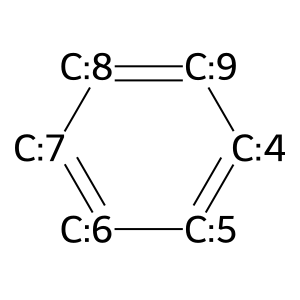

In [19]:
generate_core = input(
    "Do you wish to automatically generate core: y/n: "
)

if generate_core.upper() == "Y":
    core = MurckoScaffold.GetScaffoldForMol(parent_mol)

else:

    core_smiles = input("Enter the smiles of the core molecule")
    core = Chem.MolFromSmiles(core_smiles)

Draw.MolToImage(core)

### Generating fragments/analogues through Fragmentation/replacement of side chains

In [20]:
def attach_replacement(core, replacement, core_dummy_neighbor_original_idx):

    """
    Attach one replacement group to a selected position in the core.

    core_dummy_neighbor_original_idx:
        Original index of the core atom neighbouring the dummy.

    The replacement group must contain exactly one dummy atom,
    and that dummy must have exactly one neighbour.
    """

    # --------------------------------------------------
    # 1. Find the correct dummy in the current core
    # --------------------------------------------------

    core_info = get_core_dummy_info(core)

    matching_dummies = [
        info
        for info in core_info
        if info["core_dummy_neighbor_original_idx"]
        == core_dummy_neighbor_original_idx
    ]

    if len(matching_dummies) != 1:
        raise ValueError(
            f"Expected one dummy at original neighbour index "
            f"{core_dummy_neighbor_original_idx}, "
            f"but found {len(matching_dummies)}."
        )

    selected_dummy = matching_dummies[0]

    core_dummy_idx = selected_dummy["core_dummy_current_idx"]

    core_neighbor_idx = selected_dummy[
        "core_dummy_neighbor_current_idx"
    ]

    # --------------------------------------------------
    # 2. Find the replacement dummy and its neighbour
    # --------------------------------------------------

    replacement_dummies = [
        atom for atom in replacement.GetAtoms()
        if atom.GetAtomicNum() == 0
    ]

    if len(replacement_dummies) != 1:
        raise ValueError(
            "Replacement must contain exactly one dummy atom."
        )

    replacement_dummy = replacement_dummies[0]

    replacement_neighbors = list(
        replacement_dummy.GetNeighbors()
    )

    if len(replacement_neighbors) != 1:
        raise ValueError(
            "Replacement dummy must have exactly one neighbour."
        )

    replacement_dummy_idx = replacement_dummy.GetIdx()

    replacement_neighbor_idx = replacement_neighbors[0].GetIdx()

    # --------------------------------------------------
    # 3. Combine the molecules
    # --------------------------------------------------

    offset = core.GetNumAtoms()

    combined = Chem.CombineMols(core, replacement)

    rw_mol = Chem.RWMol(combined)

    # Replacement indices change after combining
    replacement_dummy_idx += offset
    replacement_neighbor_idx += offset

    # --------------------------------------------------
    # 4. Connect the two attachment atoms
    # --------------------------------------------------

    rw_mol.AddBond(
        core_neighbor_idx,
        replacement_neighbor_idx,
        Chem.BondType.SINGLE
    )

    # --------------------------------------------------
    # 5. Remove both dummy atoms
    # --------------------------------------------------

    dummy_indices = [
        core_dummy_idx,
        replacement_dummy_idx
    ]

    # Remove higher index first to avoid index-shifting errors
    for idx in sorted(dummy_indices, reverse=True):
        rw_mol.RemoveAtom(idx)

    # --------------------------------------------------
    # 6. Convert to a normal RDKit molecule
    # --------------------------------------------------

    new_mol = rw_mol.GetMol()

    Chem.SanitizeMol(new_mol)

    return new_mol


-----------------------------
Available molecules:
-----------------------------
0 : Parent

Choose an option:
1 - Fragment a molecule
2 - Replace a bond and create molecular analogues
3 - Display molecules
4 - Finish

Which molecule do you want to modify?
0 : Parent

Selected molecule: Parent


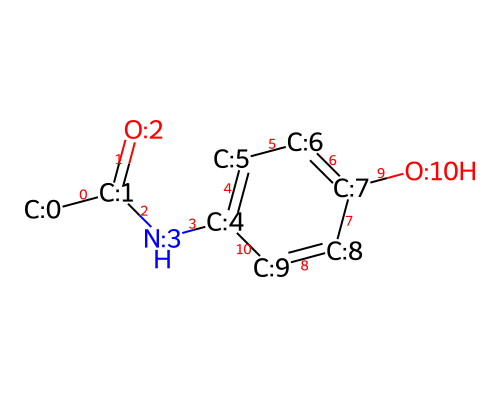


Generated core fragment:
[3*][c:4]1[cH:5][cH:6][c:7]([10*])[cH:8][cH:9]1


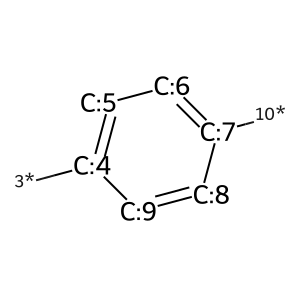


Selecting replacements for core neighbour index 4

Select categories for dummy neighbor 4
-------------------------------------------
0 | alkyl
1 | cycloalkyl
2 | alkenyl_alkynyl
3 | halogens
4 | fluoroalkyl
5 | alkoxy
6 | fluoroalkoxy
7 | oxygen
8 | amines
9 | amides
10 | carbonyl
11 | nitrile
12 | sulfur
13 | phenyl
14 | halophenyl
15 | substituted_phenyl
16 | pyridyl
17 | diazines
18 | five_membered_heteroaryl
19 | saturated_heterocycles
20 | nitrogen_carbonyl
21 | polar_groups
22 | bioisosteres
Selected categories: ['amides']

Selecting replacements for core neighbour index 7

Select categories for dummy neighbor 7
-------------------------------------------
0 | alkyl
1 | cycloalkyl
2 | alkenyl_alkynyl
3 | halogens
4 | fluoroalkyl
5 | alkoxy
6 | fluoroalkoxy
7 | oxygen
8 | amines
9 | amides
10 | carbonyl
11 | nitrile
12 | sulfur
13 | phenyl
14 | halophenyl
15 | substituted_phenyl
16 | pyridyl
17 | diazines
18 | five_membered_heteroaryl
19 | saturated_heterocycles
20 | nitrogen_car

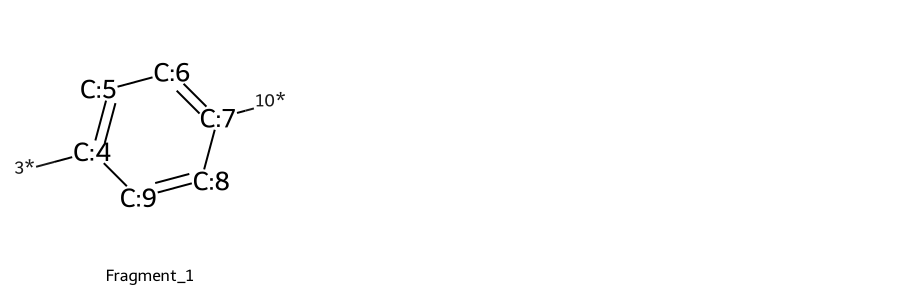


Generated molecular analogues:


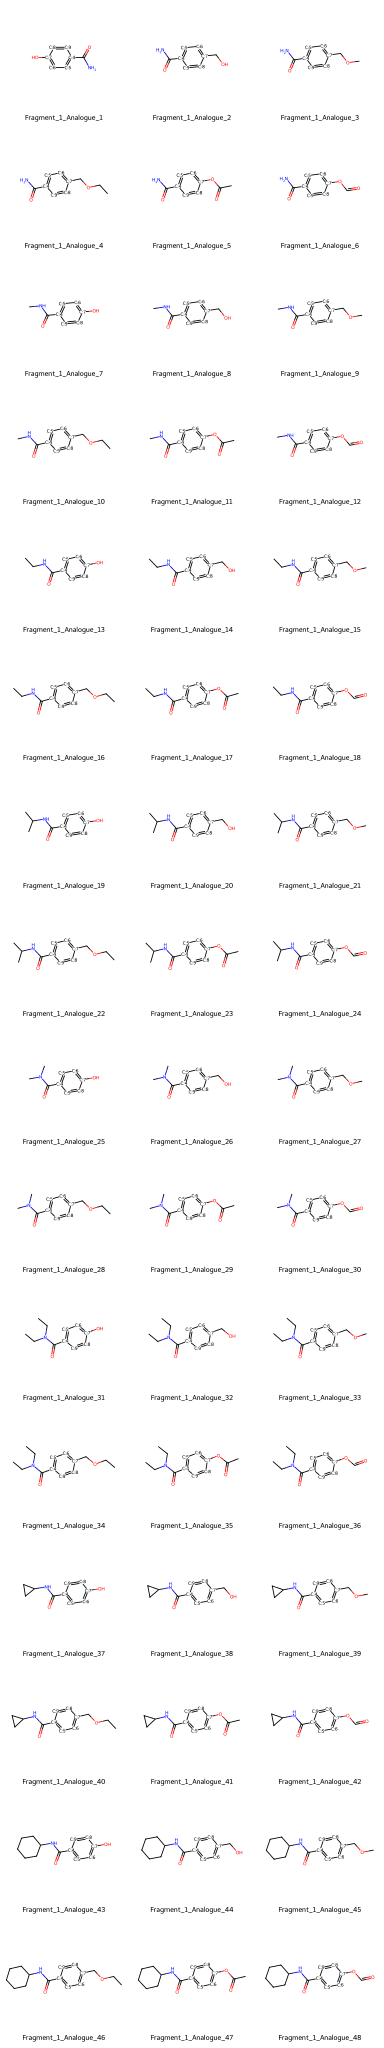

In [30]:
# -------------------------------------------------------
# INITIALIZE LIBRARIES
# -------------------------------------------------------

molecule_library = {
    "Parent": parent_mol
}

fragment_replacementlibrary = []
analogue_library = {}

fragment_counter = 0


# -------------------------------------------------------
# MAIN INTERACTIVE LOOP
# -------------------------------------------------------

while True:

    print("\n-----------------------------")
    print("Available molecules:")
    print("-----------------------------")

    names = list(molecule_library.keys())

    for i, name in enumerate(names):
        print(i, ":", name)

    print("\nChoose an option:")
    print("1 - Fragment a molecule")
    print("2 - Replace a bond and create molecular analogues")
    print("3 - Display molecules")
    print("4 - Finish")

    choice = input("Enter choice: ").strip()

    # ---------------------------------------------------
    # FINISH
    # ---------------------------------------------------

    if choice == "4":
        break

    # ---------------------------------------------------
    # DISPLAY MOLECULE LIBRARY
    # ---------------------------------------------------

    elif choice == "3":

        names = list(molecule_library.keys())
        molecules = list(molecule_library.values())

        img = Draw.MolsToGridImage(
            molecules,
            molsPerRow=3,
            subImgSize=(300, 300),
            legends=names
        )

        display(img)

        continue

    # ---------------------------------------------------
    # SELECT MOLECULE
    # ---------------------------------------------------

    elif choice in ("1", "2"):

    # Select parent molecule from molecule library
    
        print("\nWhich molecule do you want to modify?")
    
        names = list(molecule_library.keys())
        molecule_num = []
    
        for i, name in enumerate(names):
            print(i, ":", name)
            molecule_num.append(i)
    
        molecule_number = int(
            input("Enter molecule number: ")
        )
    
        if molecule_number not in molecule_num:
            print("Enter a valid number")
    
        else:
    
            parent_name = names[molecule_number]
        
            parent = molecule_library[parent_name]
        
        
    # Display selected molecule
        
            print("\nSelected molecule:", parent_name)
    
            draw_with_original_bond_indices(parent)

        # ------------------------------------------------
        # SELECT BONDS
        # ------------------------------------------------

        if choice == "1":
            atom1_idx = int(input("\nEnter first atom index of bond: "))
                
            atom2_idx = int(input("Enter second atom index of bond: "))
            
            idx1 = find_current_idx(parent, atom1_idx)
            idx2 = find_current_idx(parent, atom2_idx)
                
            # Check whether bond exists between the selected atoms
              
            bond = parent.GetBondBetweenAtoms(idx1, idx2)
                
            if bond is None:
                
                print("\nNo bond exists between these atoms.")
                
                continue
            
            # Make editable copy
            
            rw_mol = Chem.RWMol(parent)  
            
             # Break bond
            
            rw_mol.RemoveBond(idx1,idx2)
            
            # Sanitize
                
            try:
                
                 Chem.SanitizeMol(rw_mol)
                
            except Exception as e:
                
                print("\nSanitization failed:")
                print(e)
                
                continue
            
            # Fragmenting the molecule
            
            fragments = Chem.GetMolFrags(rw_mol, asMols=True)


        else:
            try:
                num_bonds = int(
                    input("How many groups do you want to replace? ")
                )

            except ValueError:
                print("Enter a valid integer.")
                continue

            if num_bonds <= 0:
                print("Enter at least one bond.")
                continue

            bond_indices = []

            invalid_selection = False

            for i in range(num_bonds):

                try:
                    bond_idx = int(
                        input(
                            f"\nEnter original bond index {i + 1}: "
                        )
                    )

                    current_bond_idx = find_current_bond_idx(
                        parent,
                        bond_idx
                    )

                    if current_bond_idx is None:
                        raise ValueError("Bond not found.")

                    bond = parent.GetBondWithIdx(
                        current_bond_idx
                    )

                    if bond is None:
                        raise ValueError("Bond not found.")

                    if current_bond_idx in bond_indices:
                        raise ValueError("Bond already selected.")

                    bond_indices.append(current_bond_idx)

                except (ValueError, RuntimeError, IndexError) as e:

                    print("Invalid bond selection:", e)

                    invalid_selection = True
                    break

                if invalid_selection:
                    continue

            # FRAGMENT SELECTED BONDS

            fragmented_mol = Chem.FragmentOnBonds(
                parent,
                bond_indices,
                addDummies=True
            )

            fragments = Chem.GetMolFrags(
                fragmented_mol,
                asMols=True
            )

        # ------------------------------------------------
        # IDENTIFY CORE FRAGMENT
        # ------------------------------------------------

        core_fragment = None

        for frag in fragments:

            if frag.HasSubstructMatch(core):

                core_fragment = frag
                break

        if core_fragment is None:

            print("Core was not found in the fragments.")
            continue

        fragment_counter += 1

        fragment_name = (
            f"{parent_name}_break_"
            f"{atom1_idx}_{atom2_idx}"
            if choice == "1"
            else f"Fragment_{fragment_counter}"
        )

        fragment_replacementlibrary.append(
            Chem.Mol(core_fragment)
        )

        fragment_smiles = Chem.MolToSmiles(
            core_fragment
        )

        print("\nGenerated core fragment:")
        print(fragment_smiles)

        display(
            Draw.MolToImage(core_fragment)
        )

        
        # -------------------------------------------------------
        # OPTION 1: STORE FRAGMENT ONLY
        # -------------------------------------------------------

        if choice == "1":

            already_exists = False

            # Check whether fragment already exists in library

            for existing_mol in molecule_library.values():

                existing_smiles = Chem.MolToSmiles(existing_mol)

                if existing_smiles == fragment_smiles:

                    already_exists = True
                    break

            # Add fragment only if it is new

            if not already_exists:

                fragment_name = (
                    f"{parent_name}_break_"
                    f"{atom1_idx}_{atom2_idx}"
                )

                molecule_library[fragment_name] = Chem.Mol(
                    core_fragment
                )

                print(
                    f"\n{fragment_name} added to molecule library."
                )

            else:

                print("\nThis fragment already exists in molecule library.")

            continue

        else:
        # ------------------------------------------------
        # OPTION 2: SELECT REPLACEMENT GROUPS
        # ------------------------------------------------

            core_info = get_core_dummy_info(
                core_fragment
            )

            selected_categories = {}

            for info in core_info:

                core_neighbor_idx = info[
                    "core_dummy_neighbor_original_idx"
                ]

                print(
                    f"\nSelecting replacements for "
                    f"core neighbour index {core_neighbor_idx}"
                )

                # Select replacement categories

                replacement_categories = select_categories(
                    core_neighbor_idx
                )

                # Collect selected groups

                replacements = collect_replacements(
                    replacement_categories
                )

                # Prepare RDKit molecules

                prepared_groups = prepare_replacement_groups(
                    replacements
                )

                # Store separately for each dummy position

                selected_categories[
                    core_neighbor_idx
                ] = prepared_groups

            # ------------------------------------------------
            # DISPLAY SELECTED REPLACEMENTS
            # ------------------------------------------------

            print("\nSelected replacement groups:")

            for position, groups in selected_categories.items():

                print(f"\nCore neighbour index {position}:")

                for group in groups:

                    print(
                        f"  - {group['name']}: {group['smiles']}"
                    )

            # ------------------------------------------------
            # GENERATE ALL POSSIBLE COMBINATIONS
            # ------------------------------------------------

            positions = list(
                selected_categories.keys()
            )

            replacement_lists = list(
                selected_categories.values()
            )

            if not positions or any(
                len(groups) == 0 for groups in replacement_lists
            ):

                print(
                    "\nNo valid replacement combinations available."
                )

                continue

            combinations = product(
                *replacement_lists
            )

            print(
                f"\nGenerating analogues for {fragment_name}"
            )

            generated_count = 0

            # ------------------------------------------------
            # ATTACH REPLACEMENT GROUPS
            # ------------------------------------------------

            for combination_idx, combination in enumerate(
                combinations,
                start=1
            ):

                # Always start with a fresh core fragment

                current_mol = Chem.Mol(
                    core_fragment
                )

                replacement_names = []

                try:

                    for position, replacement_info in zip(
                        positions,
                        combination
                    ):

                        replacement_name = replacement_info[
                            "name"
                        ]

                        replacement_mol = replacement_info[
                            "mol"
                        ]

                        current_mol = attach_replacement(
                            current_mol,
                            Chem.Mol(replacement_mol),
                            position
                        )

                        replacement_names.append(
                            replacement_name
                        )

                    # ----------------------------------------
                    # VALIDATE GENERATED ANALOGUE
                    # ----------------------------------------

                    Chem.SanitizeMol(current_mol)

                    analogue_smiles = Chem.MolToSmiles(
                        current_mol
                    )

                    # ----------------------------------------
                    # STORE GENERATED ANALOGUE
                    # ----------------------------------------

                    analogue_name = (
                        f"{fragment_name}_"
                        f"Analogue_{combination_idx}"
                    )

                    analogue_library[
                        analogue_name
                    ] = Chem.Mol(current_mol)

                    molecule_library[
                        analogue_name
                    ] = Chem.Mol(current_mol)

                    generated_count += 1

                    print(
                        analogue_name,
                        "|",
                        ", ".join(replacement_names),
                        "|",
                        analogue_smiles
                    )

                except (
                    ValueError,
                    RuntimeError,
                    Chem.rdchem.MolSanitizeException
                ) as e:

                    print(
                        f"Skipping combination "
                        f"{combination_idx}: {e}"
                    )

            print(
                f"\nSuccessfully generated "
                f"{generated_count} analogues."
            )

    else:

        print("\nInvalid choice. Select 1, 2, 3 or 4.")


# -------------------------------------------------------
# FINAL RESULTS
# -------------------------------------------------------

print("\n==========================================")
print("FINAL RESULTS")
print("==========================================")

print(
    "Number of generated fragments:",
    len(fragment_replacementlibrary)
)

print(
    "Number of generated analogues:",
    len(analogue_library)
)

print(
    "Total molecules in library:",
    len(molecule_library)
)


# -------------------------------------------------------
# DISPLAY GENERATED FRAGMENTS
# -------------------------------------------------------

if fragment_replacementlibrary:

    print("\nGenerated fragments:")

    fragment_names = [
        f"Fragment_{i + 1}"
        for i in range(len(fragment_replacementlibrary))
    ]

    display(
        Draw.MolsToGridImage(
            fragment_replacementlibrary,
            legends=fragment_names,
            molsPerRow=3,
            subImgSize=(300, 300)
        )
    )


# -------------------------------------------------------
# DISPLAY GENERATED ANALOGUES
# -------------------------------------------------------

if analogue_library:

    print("\nGenerated molecular analogues:")

    # Create fresh copies for drawing
    drawing_molecules = []

    for mol in analogue_library.values():

        mol_copy = Chem.Mol(mol)

        # Remove existing conformers and regenerate 2D coordinates
        mol_copy.RemoveAllConformers()

        rdDepictor.Compute2DCoords(mol_copy)

        drawing_molecules.append(mol_copy)

    # Display
    if drawing_molecules:

        display(
            Draw.MolsToGridImage(
                drawing_molecules,
                legends=analogue_library.keys(),
                molsPerRow=3,
                subImgSize=(300, 300),
                maxMols=len(drawing_molecules),
                useSVG=True
            )
        )
